# Intermittent Uplink Activity and Listening Requirements

This notebook combines controlled Monte Carlo validation with a paired 50-UE RT-channel study. Outputs are stored under `result/ACTIVITY_LISTENING`, alongside `result/CDF`, `result/map`, and `result/MUSIC_SNAPSHOT`.

The network study uses 20 frozen deployments, 50 NTN-UEs and 12 active sectors per deployment, five activity/noise repetitions, co-frequency 8 GHz sensing, activity probabilities 0.1, 0.3, and 1, and penalties 1e11 and 1e13. Every listening window contains 64 snapshots. Independent Bernoulli activity is a stipulated window model, not a measured traffic process.

The fixed observation seed preserves exact continuous-activity prefixes from the existing snapshot archive. Reused detections are checked numerically; intermittent cases and new budgets are evaluated afresh. No ray tracing is invoked.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
from pathlib import Path
from dataclasses import asdict
import csv
import json
import subprocess
import sys
import tempfile
from IPython.display import Image, display
from activity_experiments.config import ActivityConfig

ROOT = Path.cwd().resolve()
assert (ROOT / "activity_experiments").is_dir()
MODE = "replot"  # "new", "resume", or "replot"
RUN_DIR = ROOT / "result/ACTIVITY_LISTENING/20261026_235132_246618"
CONFIG = ActivityConfig(
    num_scenes=20, num_ntn_ues=50, repeats=5,
    p_values=(0.1, 0.3, 1.0), windows=(1, 4, 8, 16, 32, 64, 66, 96),
    snapshots_per_window=64, lambdas=(1e11, 1e13), workers=8,
)
CONFIG.validate()
print("Mode:", MODE)
print("Output directory:", RUN_DIR)
print("Requested settings for new/resume:", json.dumps(asdict(CONFIG), indent=2))

Mode: replot
Output directory: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/ACTIVITY_LISTENING/20261026_235132_246618
Requested settings for new/resume: {
  "source_run": "result/CDF/20261026_220019_877592",
  "continuous_run": "result/MUSIC_SNAPSHOT/20261026_220701_036881",
  "output_root": "result/ACTIVITY_LISTENING",
  "num_scenes": 20,
  "num_ntn_ues": 50,
  "repeats": 5,
  "p_values": [
    0.1,
    0.3,
    1.0
  ],
  "windows": [
    1,
    4,
    8,
    16,
    32,
    64,
    66,
    96
  ],
  "snapshots_per_window": 64,
  "lambdas": [
    100000000000.0,
    10000000000000.0
  ],
  "seed": 2026102803,
  "validation_seed": 2026102901,
  "synthetic_seed": 2026102902,
  "workers": 8,
  "match_angle_deg": 5.0,
  "threshold_db": -3.0,
  "bootstrap_draws": 2000,
  "coverage_trials": 100000,
  "conditional_trials": 2000
}


## Run or reuse the physical study

`replot` reads the saved run configuration and does not execute MUSIC. `resume` verifies identities and skips completed episodes. `new` creates a separate output directory with the configured seed and the same frozen RT channel population. Changing the paired observation seed requires a matching continuous-reference archive.

Each activity realization and detected direction set is shared across the two penalty weights. The beamformer sees anonymous estimated directions and powers only. Ground truth is used after detection to score active-path matches; never-transmitted users remain in the INR population.

In [2]:
assert MODE in {"new", "resume", "replot"}
if MODE in {"new", "resume"}:
    with tempfile.TemporaryDirectory(prefix="activity_config_") as temporary:
        config_path = Path(temporary) / "config.json"
        config_path.write_text(json.dumps(asdict(CONFIG)))
        command = [sys.executable, "-m", "activity_experiments", "run",
                   "--config", str(config_path), "--workers", str(CONFIG.workers)]
        if MODE == "resume":
            command += ["--directory", str(RUN_DIR)]
        subprocess.run(command, cwd=ROOT, check=True)
    if MODE == "new":
        RUN_DIR = Path(json.loads((ROOT / CONFIG.output_root / "latest_run.json").read_text())["directory"])
assert (RUN_DIR / "run_config.json").is_file()
SAVED_CONFIG = json.loads((RUN_DIR / "run_config.json").read_text())["config"]
print("Saved run:", RUN_DIR)
print("Scenes / repeats / UEs:", SAVED_CONFIG["num_scenes"], SAVED_CONFIG["repeats"], SAVED_CONFIG["num_ntn_ues"])

Saved run: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/ACTIVITY_LISTENING/20261026_235132_246618
Scenes / repeats / UEs: 20 5 50


## Controlled simulations and aggregate analysis

The activity-only experiment uses 100,000 independent trials per operating point with 50 protected users. The conditional INR experiment uses one source and eight antennas, matching the analytical benchmark rather than the full network. It uses exact covariance sampling checked against direct observation matrices, with 2,000 trials per condition. The active-only reference uses unavailable activity truth and is labeled as an oracle diagnostic.

Network intervals resample independent deployments while retaining paired repetitions, activity probabilities, budgets, and penalties. Timing uses one listening window as the time unit: H=256, switching=0.1, inter-window gap=1, and processing=1. MRT is used before the final beam is ready. Sensitivities at H=512 and H=1024 are reported separately; these are protocol assumptions, not measured hardware delays.

In [3]:
from activity_experiments.analysis import analyze
from activity_experiments.synthetic import run_synthetic
from activity_experiments.plotting import plot
from activity_experiments.finalize import finish

if not (RUN_DIR / "synthetic/config.json").exists():
    run_synthetic(RUN_DIR)
else:
    print("Using archived synthetic Monte Carlo results.")
analyze(RUN_DIR)
plot(RUN_DIR)
finish(RUN_DIR)

Using archived synthetic Monte Carlo results.


Analyzed 100 episodes: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/ACTIVITY_LISTENING/20261026_235132_246618


Figures generated: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/ACTIVITY_LISTENING/20261026_235132_246618


Completed and independently checked: /home/shizhen/my_project/NTN-NULLING-NONCOH-transaction/result/ACTIVITY_LISTENING/20261026_235132_246618


## Compact figures selected for the paper

The first figure tests the conditional single-source INR approximation. The second pairs activity-coverage failure with the final-beam INR exceedance fraction at a publication threshold of -6 dB and lambda = 1e13. This threshold corresponds to about 0.97 dB noise-plus-interference rise. The earlier -3 dB figure is preserved as `activity_coverage_protection_ab_minus3db.pdf/png`.

Activity coverage concerns all 50 deployed users; physical INR uses the fixed subset with nonzero RT links, including silent and undetected users. Neither panel includes service-time costs. The publication-specific means and deployment-bootstrap intervals are recalculated from archived INR samples and saved in `protection_minus6db_summary.csv` and `protection_minus6db_arrays.npz`. The original -3 dB experiment configuration and diagnostic metrics are retained.

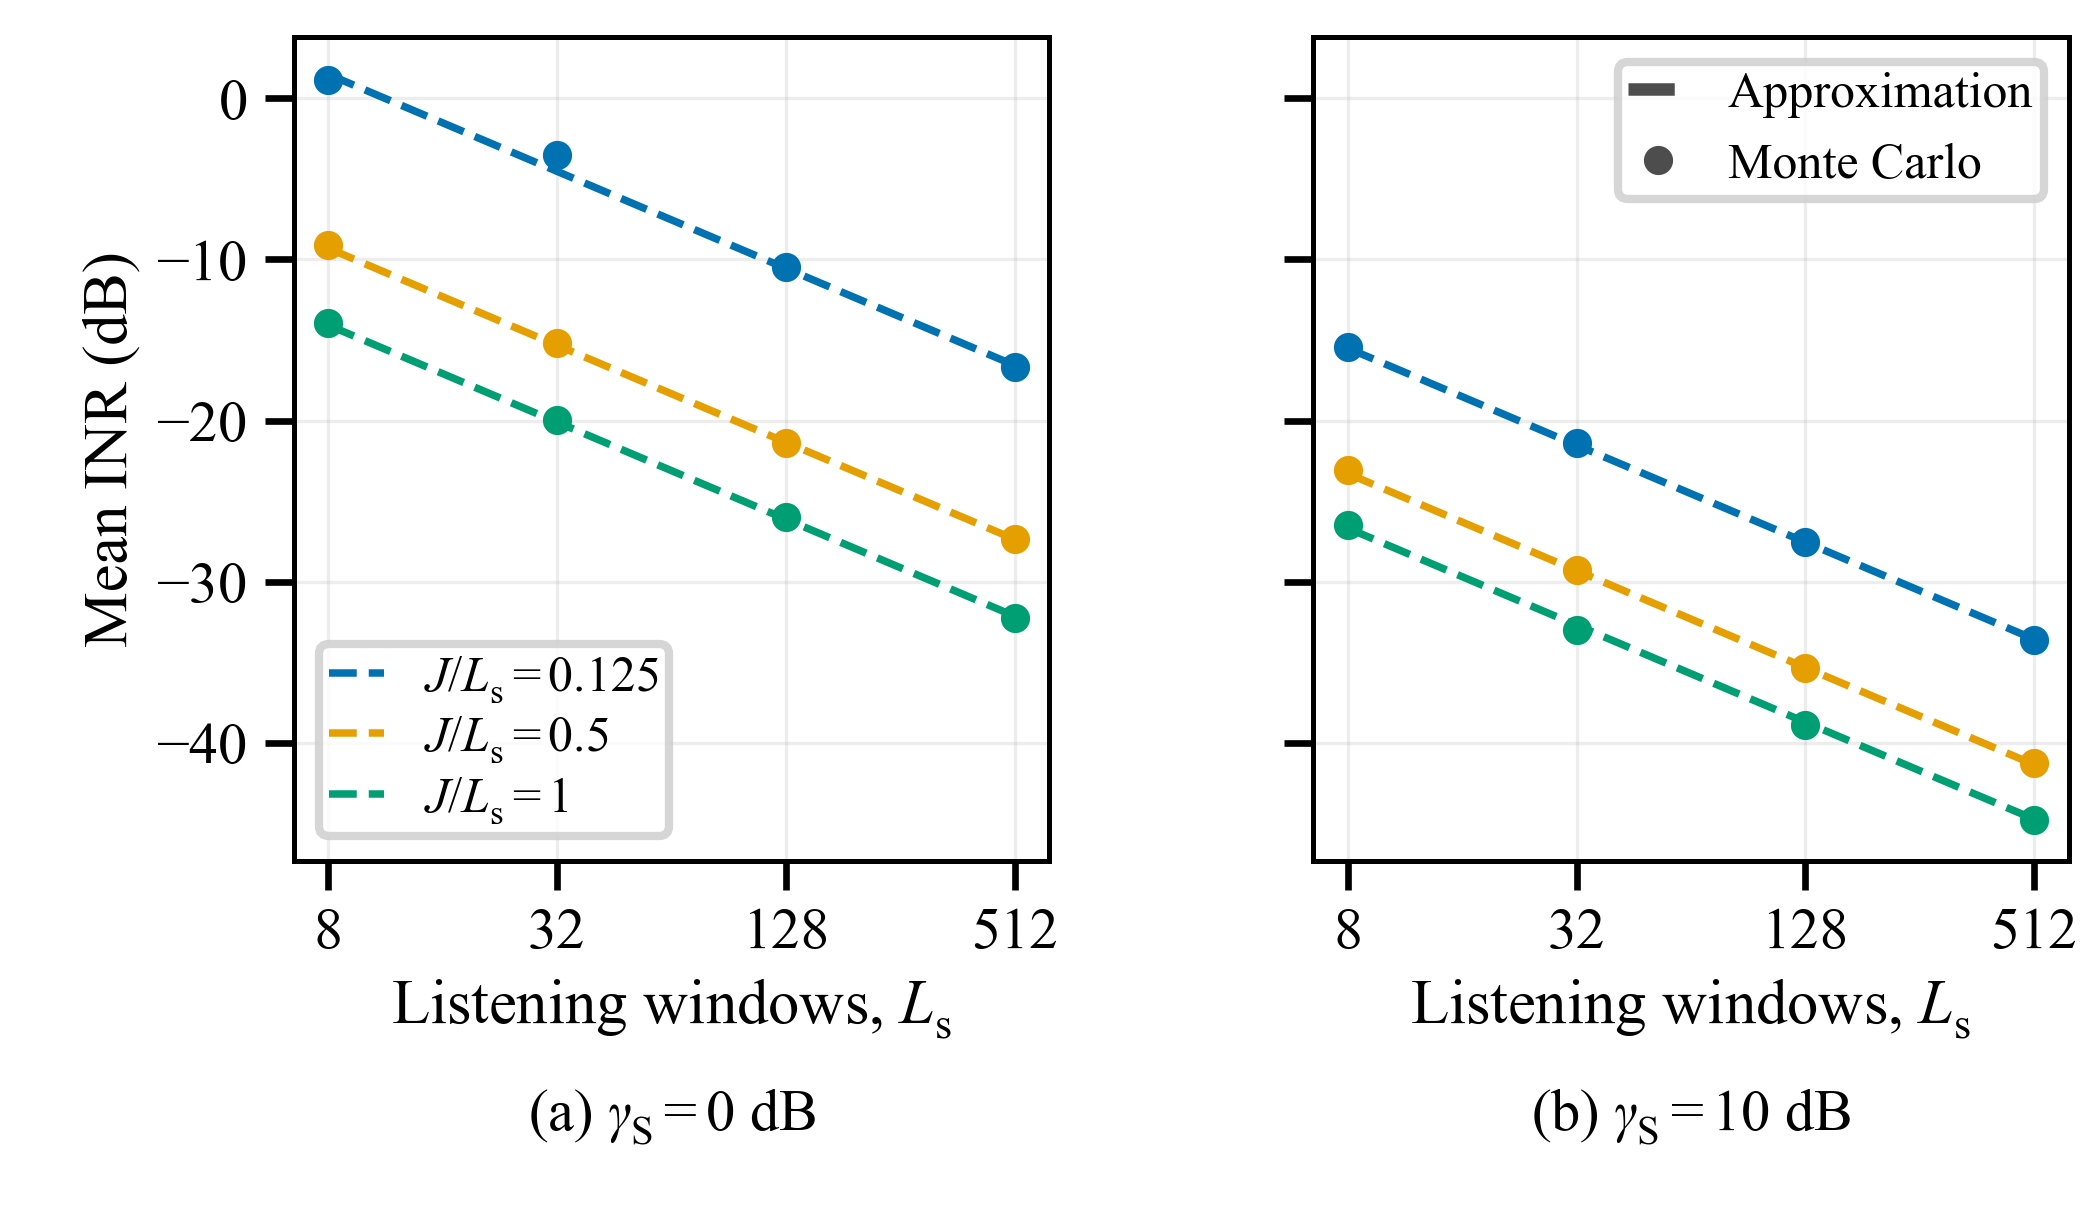

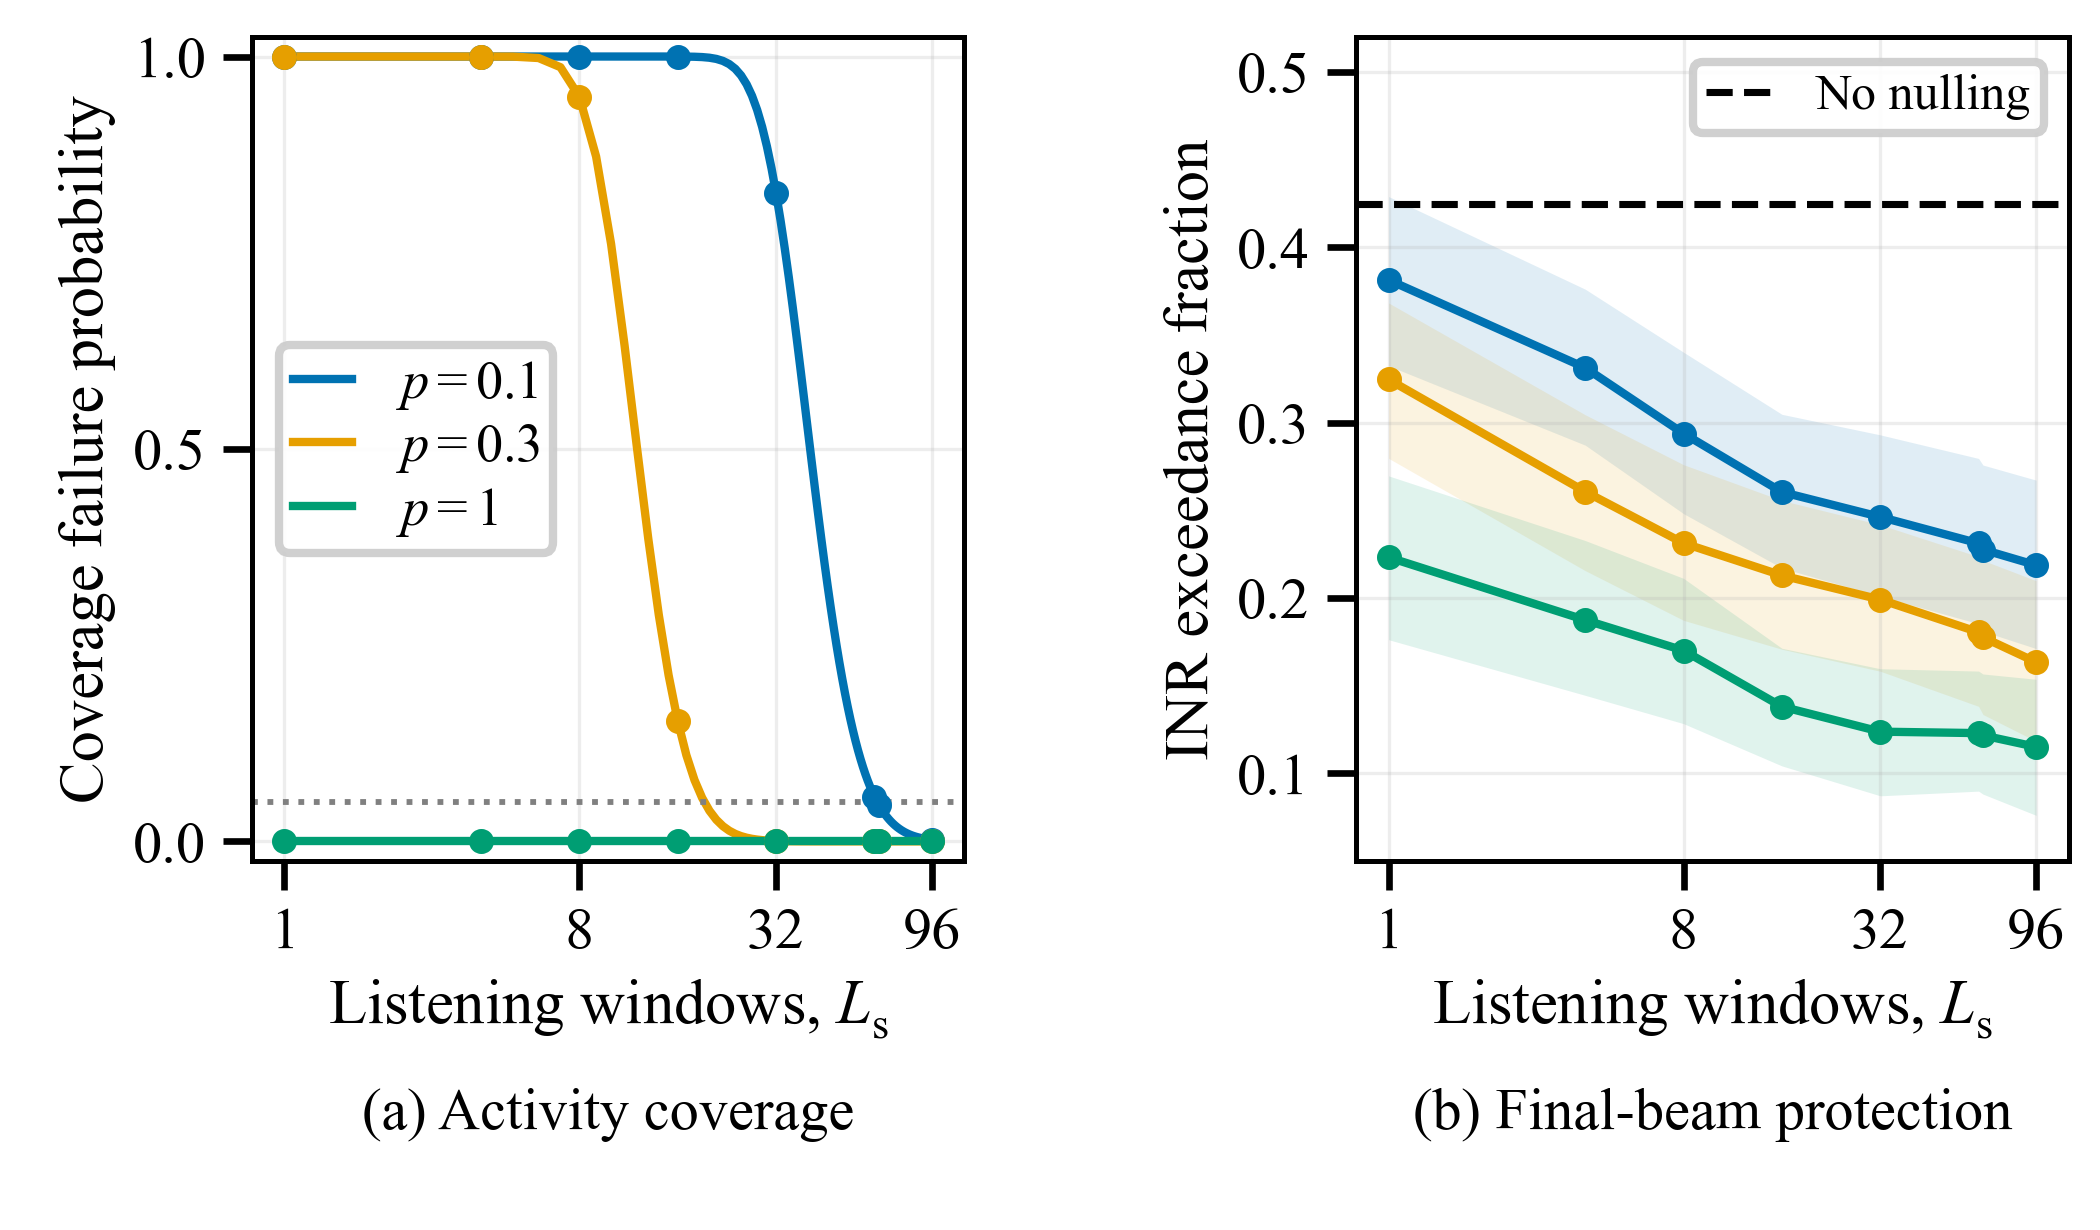

In [4]:
display(Image(filename=str(RUN_DIR / "synthetic_conditional_inr_ab.png")))
display(Image(filename=str(RUN_DIR / "activity_coverage_protection_ab_minus6db.png")))

## Network diagnostics

The diagnostic curves distinguish final-beam risk from risk during all data transmission and effective TN service. The failure decomposition partitions every evaluated linked UE into never transmitted, transmitted but unmatched, or transmitted and matched. The supplementary INR CDF retains the fixed linked population, including undetected users; its deterministic baseline is counted once.

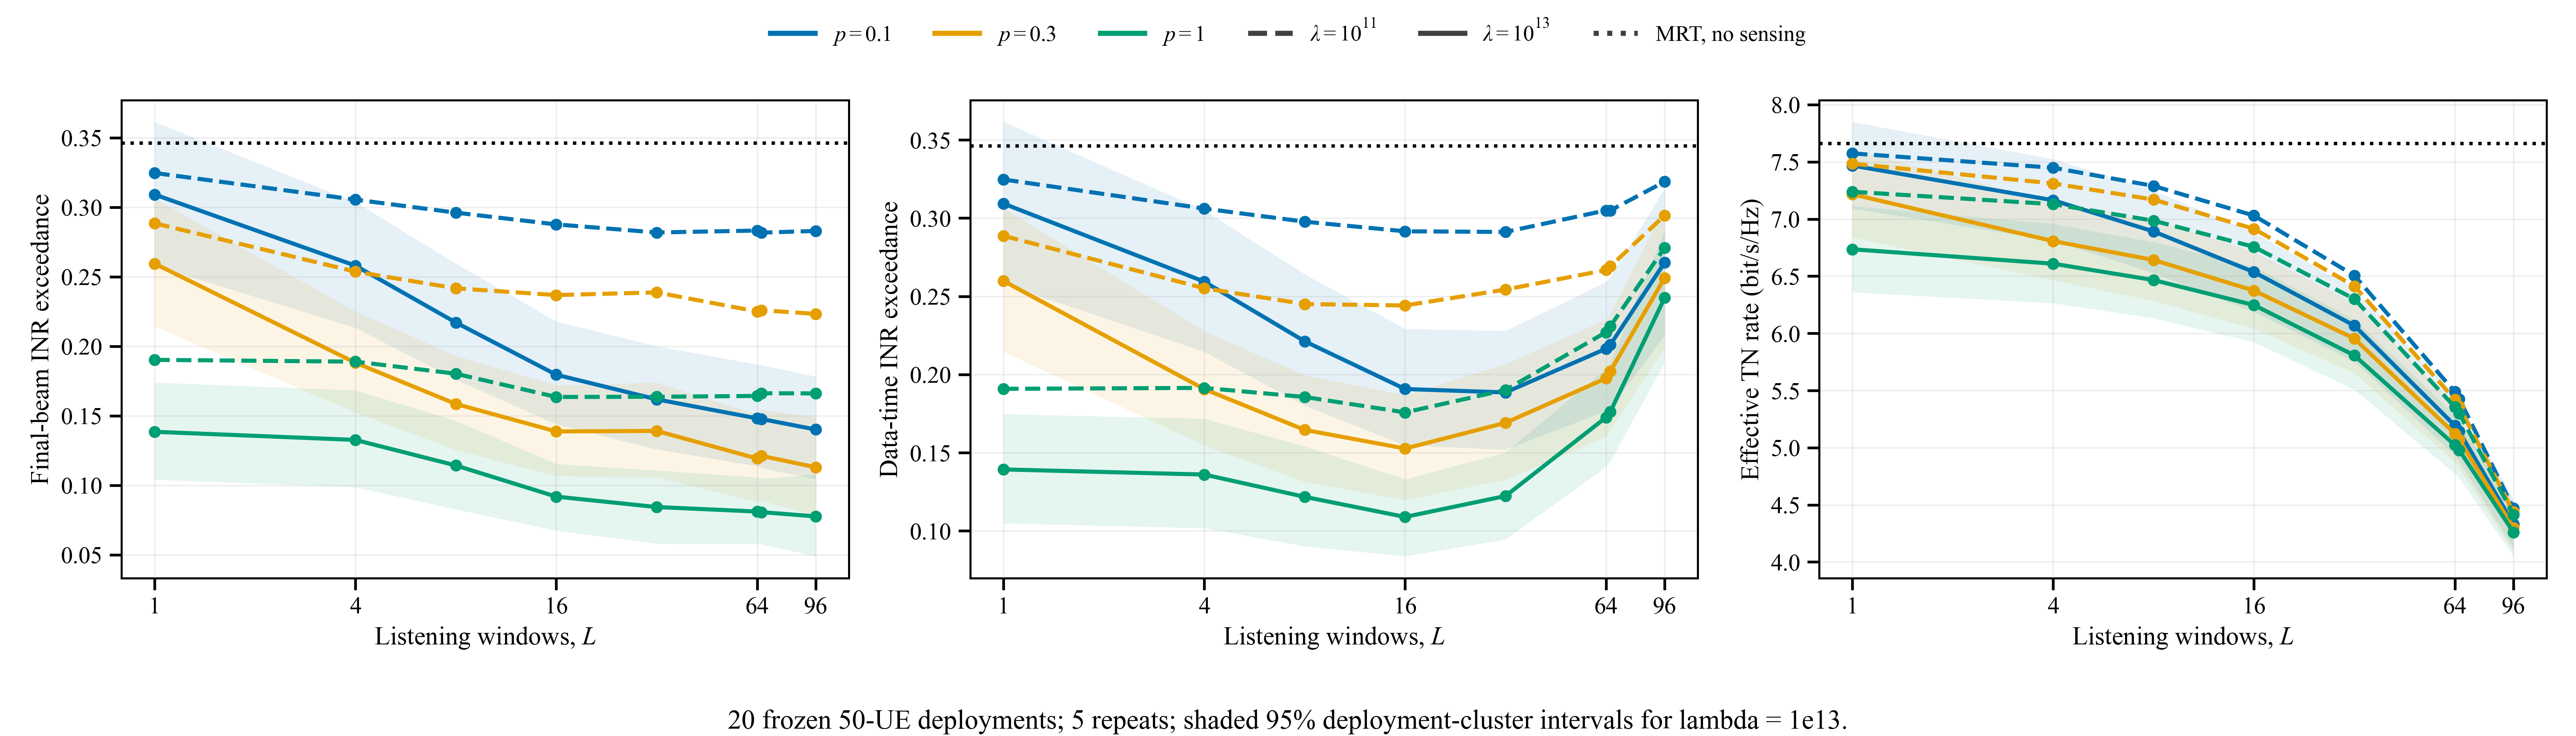

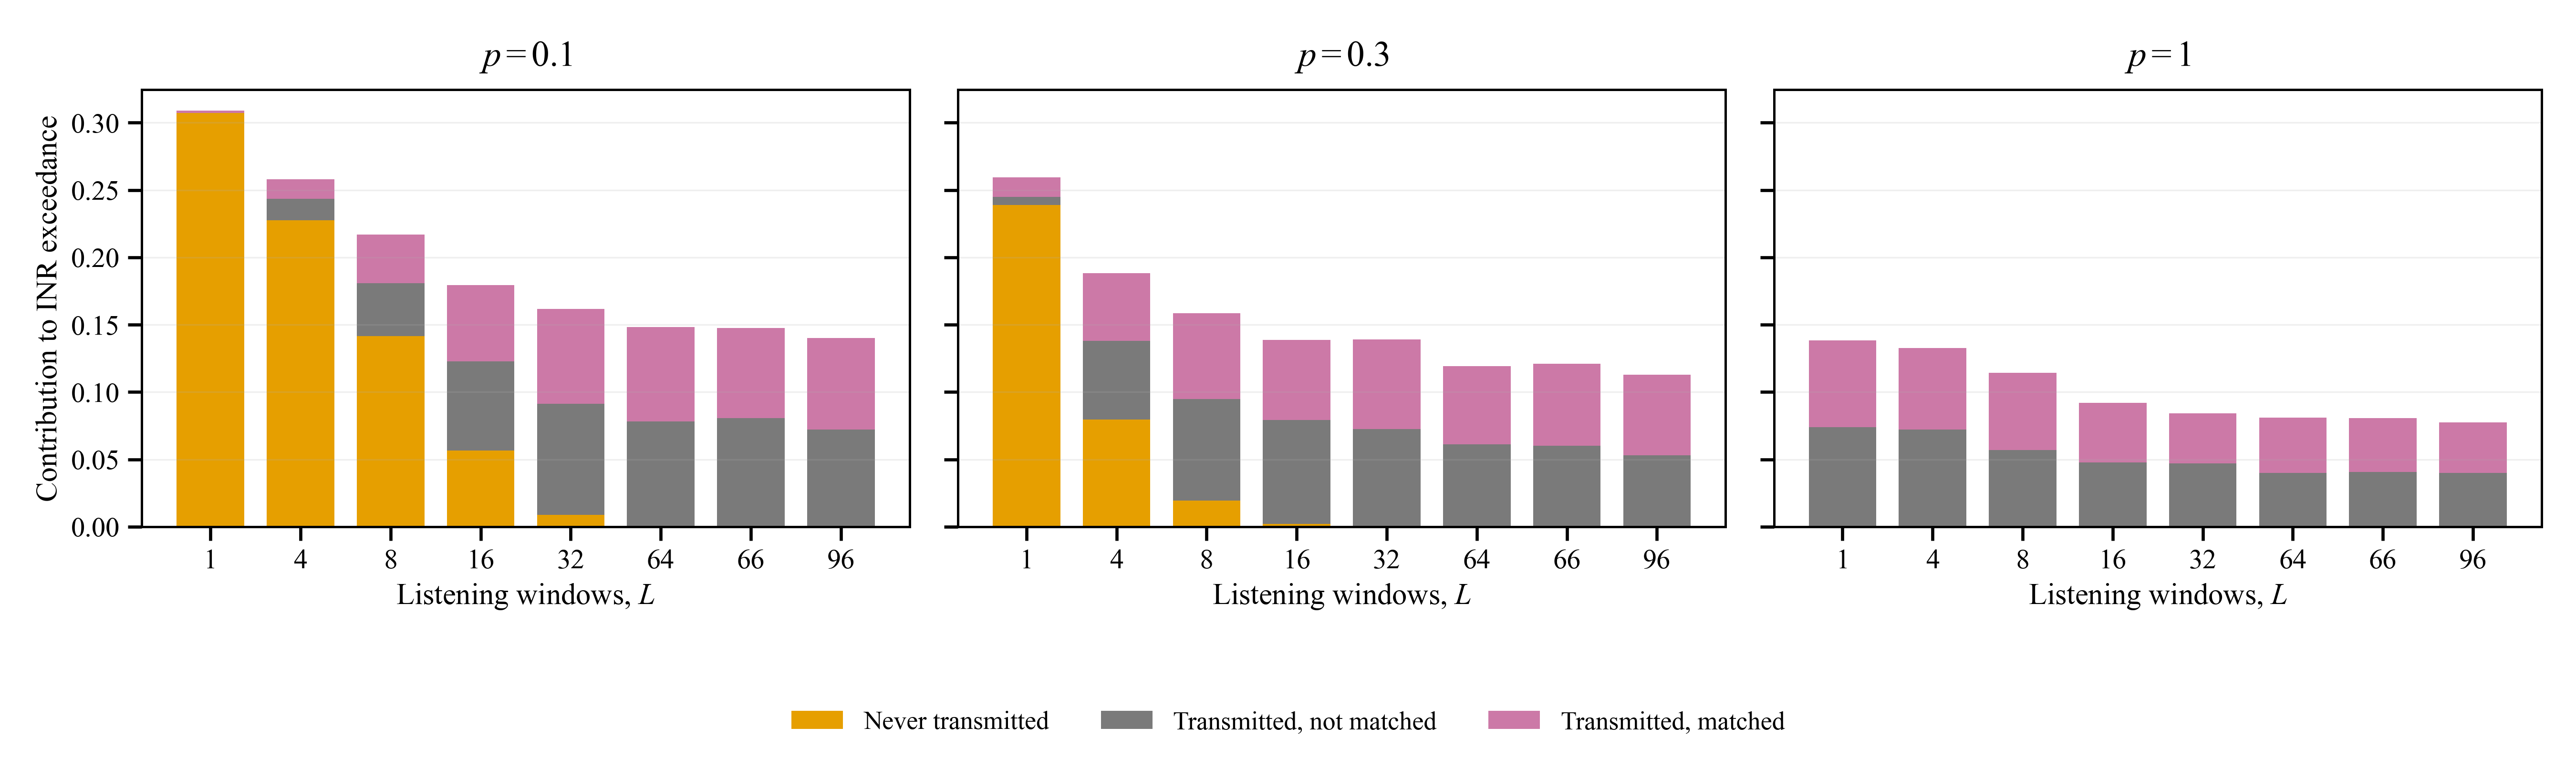

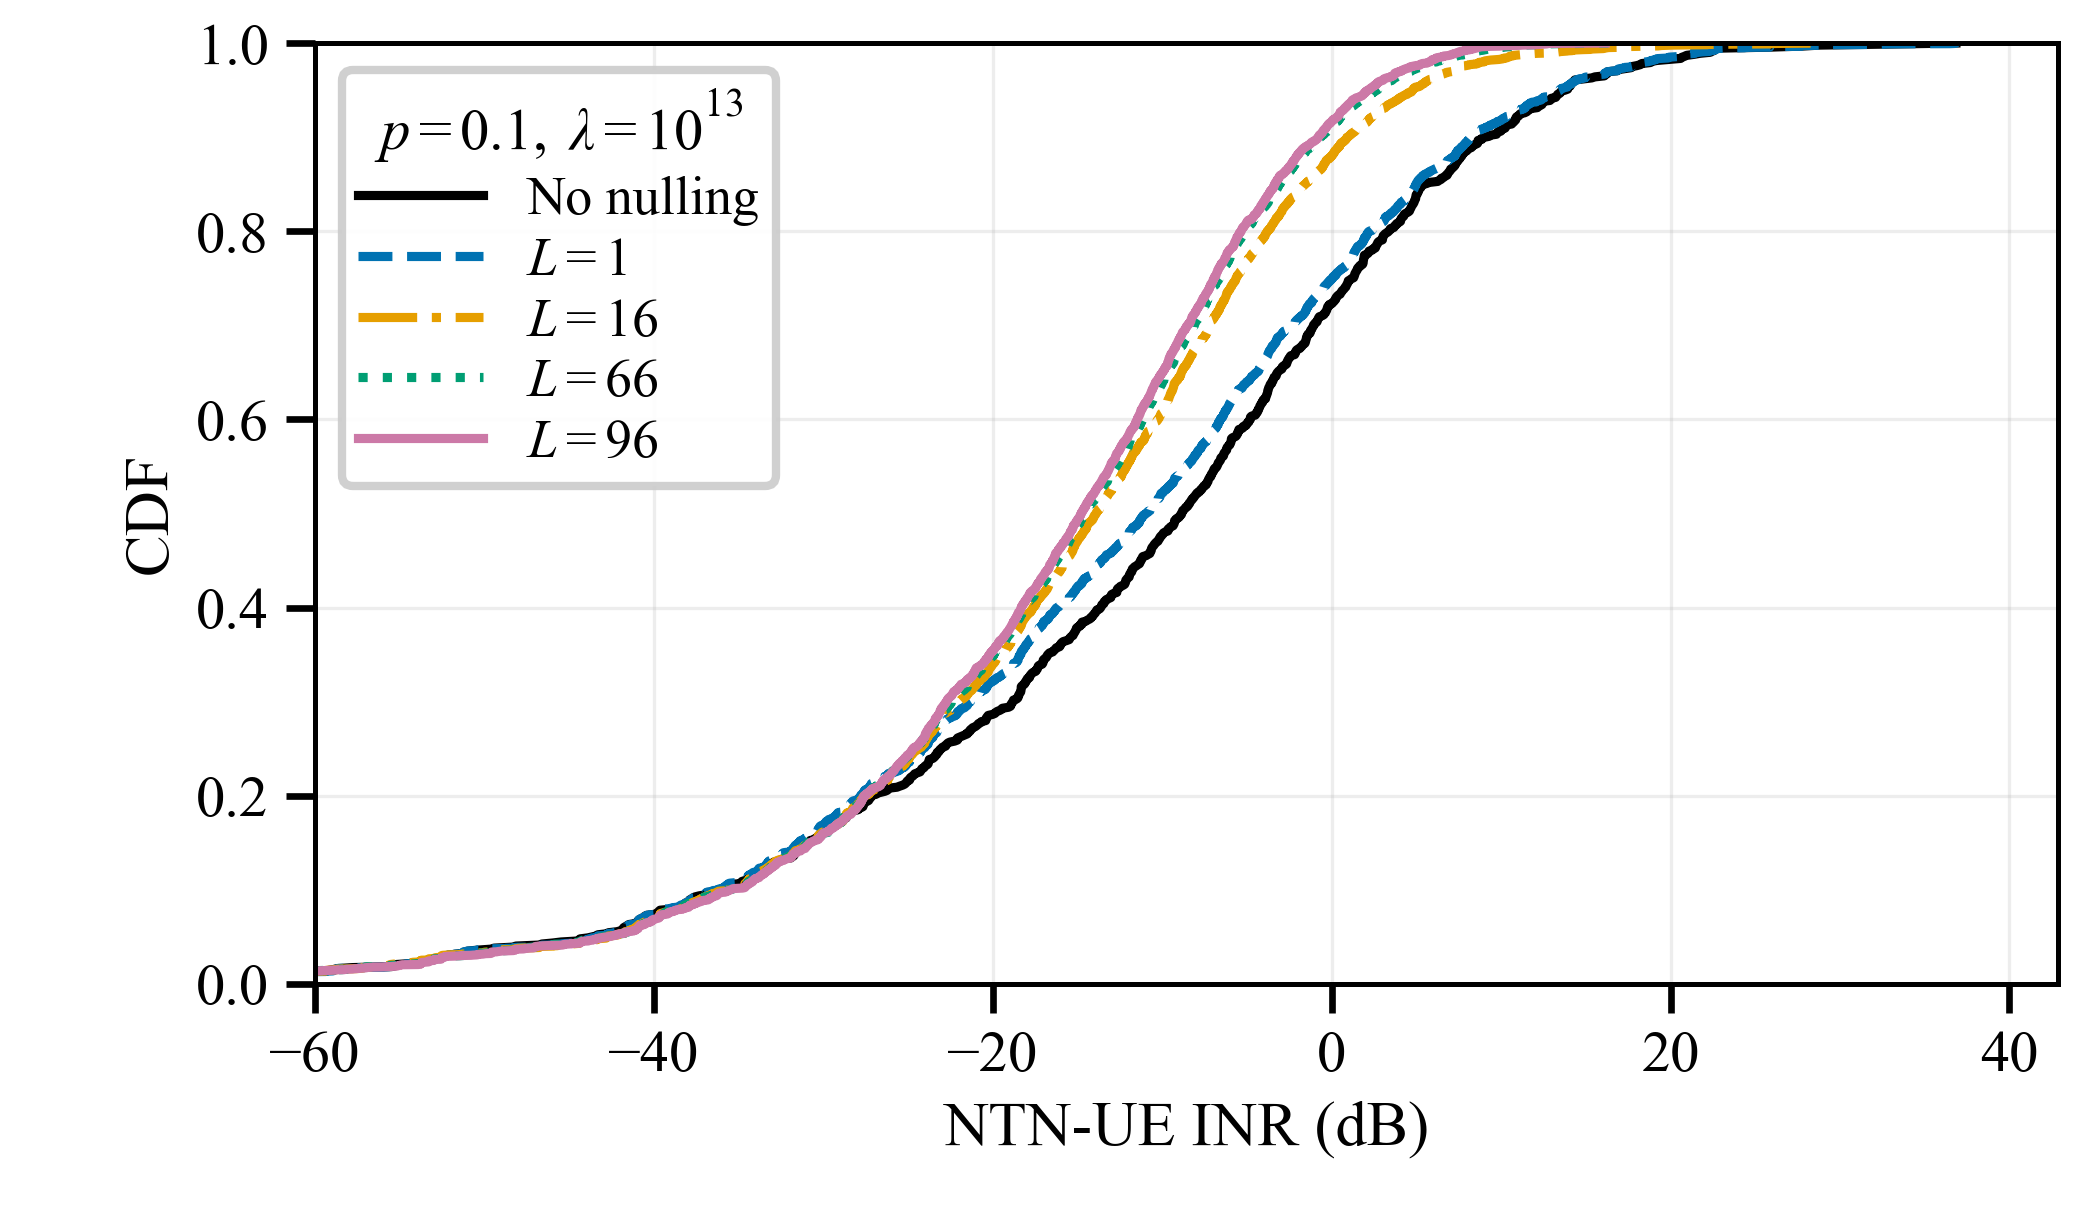

In [5]:
display(Image(filename=str(RUN_DIR / "activity_rt_diagnostics.png")))
display(Image(filename=str(RUN_DIR / "activity_failure_breakdown.png")))
display(Image(filename=str(RUN_DIR / "activity_inr_cdf.png")))

In [6]:
report = json.loads((RUN_DIR / "results_summary.json").read_text())
print("Legacy diagnostics at -3 dB:")
print("p     L    Final INR exceedance    Data-time exceedance    Effective TN rate")
for row in report["rt"]:
    if row["lambda_value"] == 1e13 and row["L"] in [1, 16, 66, 96]:
        print(f'{row["p"]:<5g} {row["L"]:<4d} {100*row["q_out"]:>8.2f}% {100*row["q_data"]:>22.2f}% {row["r_eff"]:>23.3f}')
print("Validation:", json.loads((RUN_DIR / "independent_validation.json").read_text()))
print("Status:", json.loads((RUN_DIR / "status.json").read_text()))
print("Paper figure at -6 dB: p, L, final exceedance (%)")
with (RUN_DIR / "protection_minus6db_summary.csv").open() as stream:
    for row in csv.DictReader(stream):
        if float(row["lambda_value"]) == 1e13 and int(row["L"]) in [1, 16, 66, 96]:
            print(row["p"], row["L"], round(100*float(row["q_out"]), 2))


Legacy diagnostics at -3 dB:
p     L    Final INR exceedance    Data-time exceedance    Effective TN rate
0.1   1       30.91%                  30.93%                   7.468
0.1   16      17.95%                  19.07%                   6.536
0.1   66      14.76%                  21.91%                   5.141
0.1   96      14.01%                  27.16%                   4.332
0.3   1       25.94%                  25.98%                   7.216
0.3   16      13.87%                  15.26%                   6.374
0.3   66      12.11%                  20.21%                   5.069
0.3   96      11.29%                  26.18%                   4.299
1     1       13.85%                  13.93%                   6.735
1     16       9.18%                  10.89%                   6.247
1     66       8.06%                  17.62%                   4.979
1     96       7.76%                  24.90%                   4.259
Validation: {'activity_prefixes_and_matching': True, 'all_snapshot